<a href="https://colab.research.google.com/github/IvanovaKaryna/-/blob/main/%D0%9B%D0%914_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_3_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

In [3]:
#Завантаження датасету
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

Using Colab cache for faster access to the 'car-price-prediction' dataset.


In [4]:
# Перегляд перших рядків
display(df.head())


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [5]:
# Кількість об'єктів і ознак
print("Розмір датасету:", df.shape)
print("Кількість об'єктів:", df.shape[0])
print("Кількість ознак:", df.shape[1])

Розмір датасету: (205, 26)
Кількість об'єктів: 205
Кількість ознак: 26


In [6]:
# Назви стовпців
print("\nНазви стовпців:")
print(df.columns.tolist())



Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [7]:
# Типи даних
print("\nТипи даних:")
print(df.dtypes)


Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object


In [8]:
# Загальна інформація про датасет
print("\nІнформація про датасет:")
df.info()


Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        2

In [10]:
# Основні статистичні характеристики
print("\nОсновні статистичні характеристики:")
display(df.describe())


Основні статистичні характеристики:


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [11]:
# Цільова змінна
print("Цільова змінна: price")

Цільова змінна: price


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [12]:
#перевірка пропущених значень
print("Кількість пропущених значень:")
print(df.isnull().sum())

Кількість пропущених значень:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [15]:
#Перевірка повних дублікатів
print("Повні дублікати:", df.duplicated().sum())

#Перевірка дублікатів без урахування car_ID
print("Дублікати без car_ID:",
      df.drop(columns=["car_ID"]).duplicated().sum())

Повні дублікати: 0
Дублікати без car_ID: 0


In [16]:
#Кількість унікальних значень у кожному стовпці
print("Кількість унікальних значень:")
print(df.nunique())

Кількість унікальних значень:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [17]:
car_ids = df["car_ID"].copy()

# Видалення car_ID з ознак
df = df.drop(columns=["car_ID"])

print("Ідентифікатори збережено окремо.")
print("Кількість ID:", len(car_ids))
print("Кількість ознак після видалення car_ID:", df.shape[1])

Ідентифікатори збережено окремо.
Кількість ID: 205
Кількість ознак після видалення car_ID: 25


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [18]:
# Вибір числових ознак без цільової змінної price
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop("price")

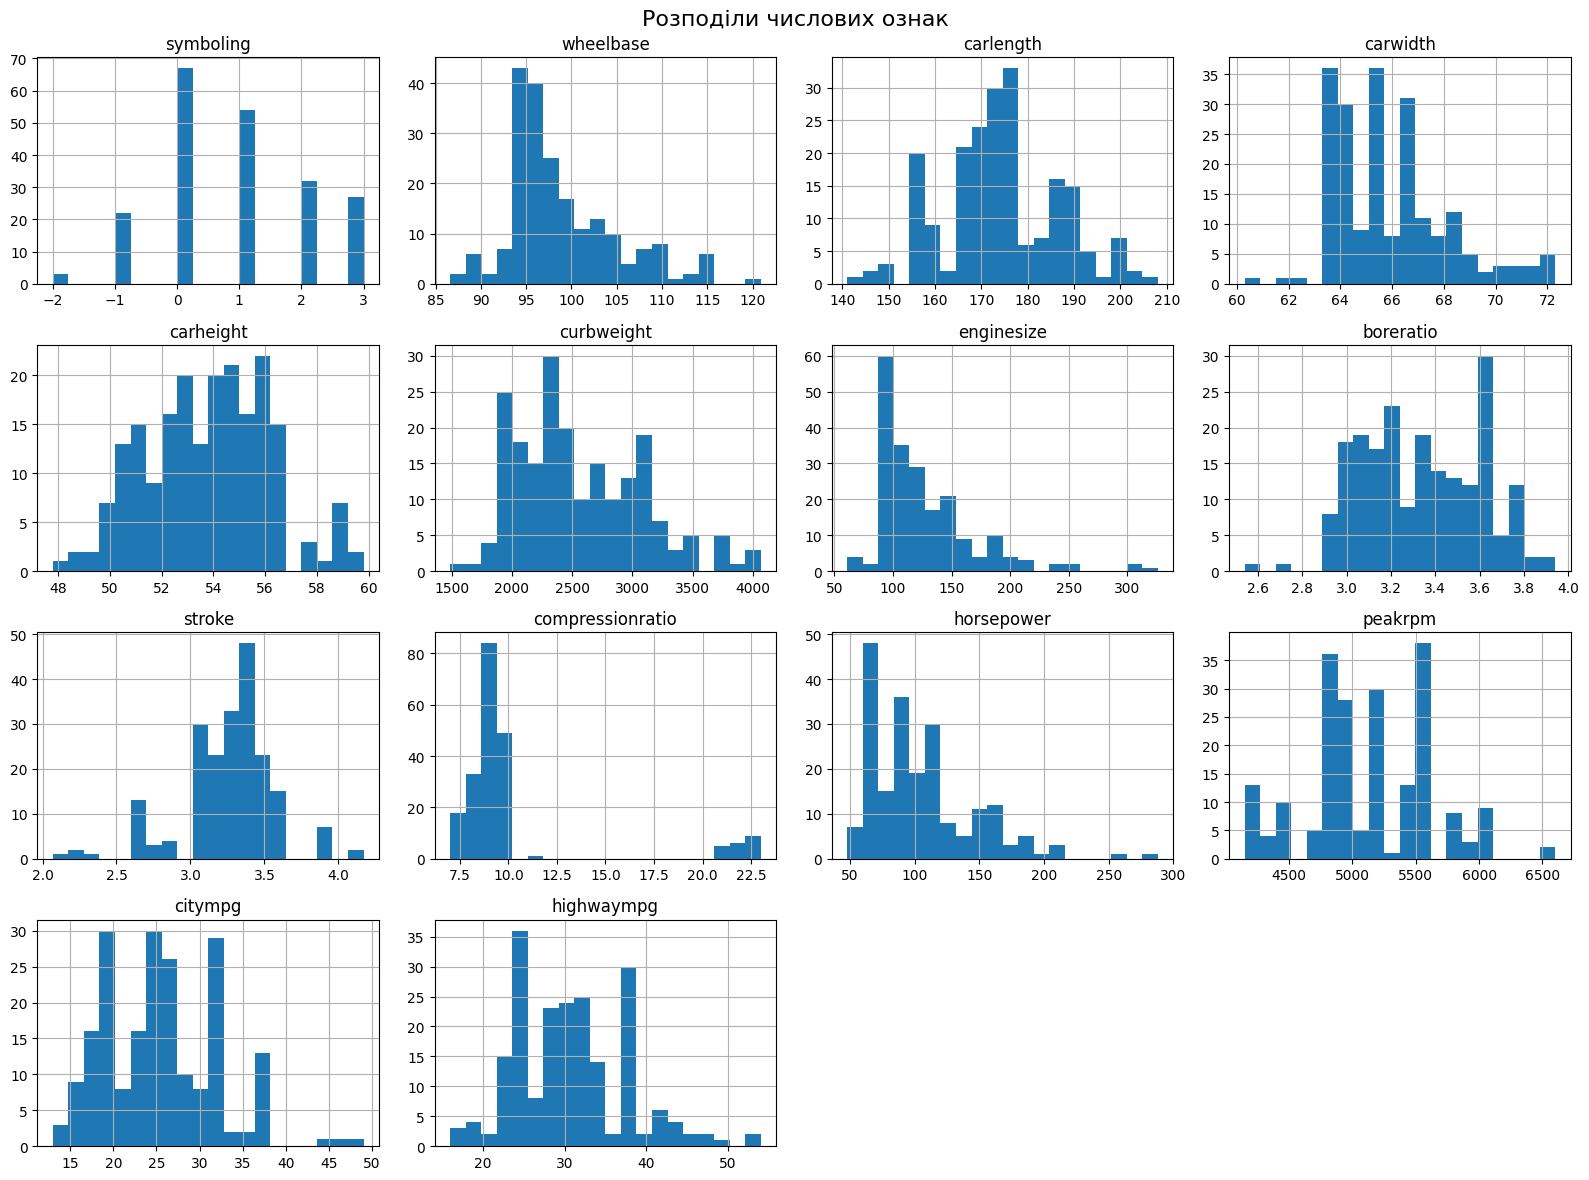

In [19]:
#Побудова гістограм
df[numeric_cols].hist(figsize=(16, 12), bins=20)
plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
#Обчислення коефіцієнтів асиметрії
skew_values = df[numeric_cols].skew().sort_values(
    key=abs, ascending=False
)

In [21]:
print("Коефіцієнти асиметрії:")
display(skew_values)
print("Найбільш асиметричні ознаки:")
display(skew_values.head(5))

Коефіцієнти асиметрії:


,0
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


Найбільш асиметричні ознаки:


,0
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003


За результатами аналізу найбільшу асиметрію мають ознаки `compressionratio`, `enginesize` та `horsepower`. Більшість числових ознак мають додатну асиметрію, тобто їхні розподіли зміщені вправо.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids,
    test_size=0.2,
    random_state=42
)
print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)
print("Кількість ID у train:", len(id_train))
print("Кількість ID у test:", len(id_test))

Розмір навчальної вибірки: (164, 24)
Розмір тестової вибірки: (41, 24)
Кількість ID у train: 164
Кількість ID у test: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [23]:
#Неперервні числові ознаки
continuous_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.drop("symboling")

#Збереження меж викидів
outlier_bounds = {}

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower, upper)

    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    print(f"{col}: {count} потенційних викидів")

#Обмеження значень межами, визначеними на train
X_train = X_train.copy()
X_test = X_test.copy()

for col in continuous_cols:
    lower, upper = outlier_bounds[col]

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("Обробку викидів завершено.")

wheelbase: 6 потенційних викидів
carlength: 0 потенційних викидів
carwidth: 10 потенційних викидів
carheight: 0 потенційних викидів
curbweight: 0 потенційних викидів
enginesize: 7 потенційних викидів
boreratio: 1 потенційних викидів
stroke: 16 потенційних викидів
compressionratio: 20 потенційних викидів
horsepower: 7 потенційних викидів
peakrpm: 2 потенційних викидів
citympg: 0 потенційних викидів
highwaympg: 1 потенційних викидів
Обробку викидів завершено.


Для виявлення потенційних викидів я використала метод IQR, який визначає межі за першим і третім квартилями. Значення за межами цих інтервалів вважаються потенційними викидами, але не обов’язково є помилковими даними.

Оскільки набір даних невеликий, я не видаляла рядки з викидами, щоб не втратити важливу інформацію про автомобілі. Натомість крайні значення обмежила нижньою та верхньою межами, розрахованими за навчальною вибіркою. Цільову змінну price не використовувала для визначення викидів. До тестової вибірки застосувала ті самі межі, що й до навчальної, щоб уникнути витоку даних

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


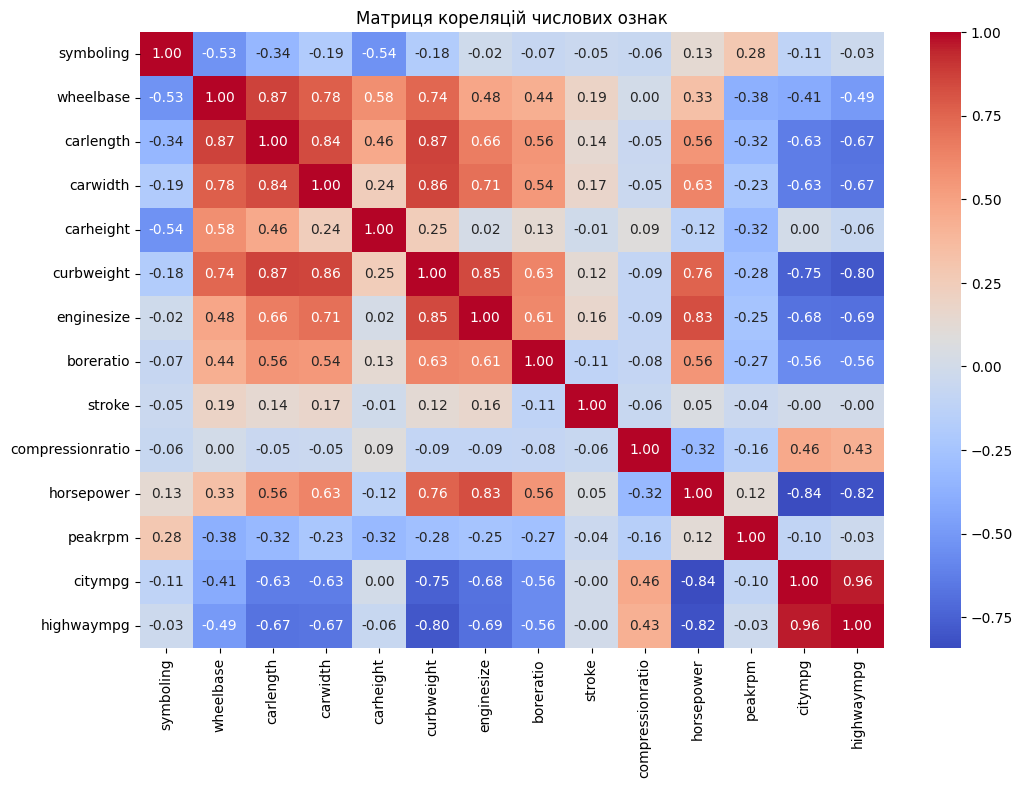

Сильно корельовані пари:
wheelbase — carlength: r = 0.867
carlength — curbweight: r = 0.866
carwidth — curbweight: r = 0.858
citympg — highwaympg: r = 0.964

Ознаки, які видаляються:
['carlength', 'carwidth', 'citympg', 'wheelbase']


In [24]:
#Числові ознаки навчальної вибірки
numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns

#Матриця кореляцій
corr_matrix = X_train[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Матриця кореляцій числових ознак")
plt.show()

#Зв'язок ознак із цільовою змінною
price_corr = X_train[numeric_cols].corrwith(y_train).abs()

#Пошук сильно корельованих пар
strong_pairs = []

for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col1 = numeric_cols[i]
        col2 = numeric_cols[j]
        r = corr_matrix.loc[col1, col2]

        if abs(r) > 0.85:
            strong_pairs.append((col1, col2, r))

#Вибір ознак для видалення
drop_features = set()

print("Сильно корельовані пари:")

for col1, col2, r in strong_pairs:
    print(f"{col1} — {col2}: r = {r:.3f}")

    if col1 in drop_features:
        continue
    if col2 in drop_features:
        continue

    if price_corr[col1] >= price_corr[col2]:
        drop_features.add(col2)
    else:
        drop_features.add(col1)

print("\nОзнаки, які видаляються:")
print(sorted(drop_features))

#Видалення однакових ознак із train і test
X_train = X_train.drop(columns=list(drop_features))
X_test = X_test.drop(columns=list(drop_features))

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [25]:
#Розділення ознак за типами
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

continuous_features = [
    col for col in numeric_features if col != "symboling"
]

symboling_features = ["symboling"] if "symboling" in X_train.columns else []

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Неперервні числові ознаки:", continuous_features)
print("Дискретна ознака:", symboling_features)
print("Категоріальні ознаки:", categorical_features)

#Передобробка неперервних числових ознак
continuous_transformer = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

symboling_transformer = StandardScaler()

#Кодування категоріальних ознак
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

#Об'єднання всіх перетворень
preprocessor = ColumnTransformer([
    ("continuous", continuous_transformer, continuous_features),
    ("symboling", symboling_transformer, symboling_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Передобробку даних налаштовано.")

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна ознака: ['symboling']
Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
Передобробку даних налаштовано.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [26]:
#Початкова асиметрія
skew_before = X_train[continuous_features].skew()

#Навчання передобробки тільки на train
preprocessor.fit(X_train)

#Перетворення неперервних ознак
transformed_numeric = preprocessor.named_transformers_[
    "continuous"
].transform(X_train[continuous_features])

#Асиметрія після перетворення
transformed_df = pd.DataFrame(
    transformed_numeric,
    columns=continuous_features,
    index=X_train.index
)

skew_after = transformed_df.skew()

#Порівняння результатів
skew_comparison = pd.DataFrame({
    "До перетворення": skew_before,
    "Після перетворення": skew_after
})

display(skew_comparison.round(3))

,До перетворення,Після перетворення
carheight,0.028,-0.005
curbweight,0.712,0.050
enginesize,0.962,0.045
boreratio,0.063,-0.006
stroke,-0.398,0.016
compressionratio,0.056,0.005
horsepower,0.851,0.066
peakrpm,0.040,-0.004
highwaympg,0.244,-0.012


Після перетворення Yeo–Johnson асиметрія більшості числових ознак зменшилася. Це перетворення допомогло зробити їхні розподіли більш симетричними

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [27]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR()
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

print("Створено 6 регресійних моделей.")

Створено 6 регресійних моделей.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [28]:
results = []
predictions = {}

for name, pipeline in pipelines.items():
    #навчання моделі
    pipeline.fit(X_train, y_train)

    #прогноз для тестової вибірки
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    #метрики
    results.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
        "R2 train": r2_score(y_train, pipeline.predict(X_train))
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("R2", ascending=False).reset_index(drop=True)

display(results_df.round(3))

,Модель,R2,MAE,MSE,"MAPE, %",R2 train
0,Random Forest,0.951,1446.898,3.900439e+06,10.497,0.985
1,Gradient Boosting,0.930,1684.462,5.560430e+06,12.591,0.992
2,Ridge Regression,0.796,2712.716,1.612918e+07,23.064,0.962
3,Lasso Regression,0.706,3088.990,2.320280e+07,22.608,0.991
4,Linear Regression,0.548,4078.302,3.567898e+07,29.973,0.993
5,SVR,-0.100,5696.454,8.681160e+07,36.024,-0.108


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни автомобіля належить до задач регресії, оскільки `price` є неперервною числовою величиною. Logistic Regression використовується для класифікації та визначення належності до класу, тому вона не підходить для безпосереднього прогнозування ціни. У роботі я використала регресійні моделі, які дають змогу прогнозувати числові значення

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


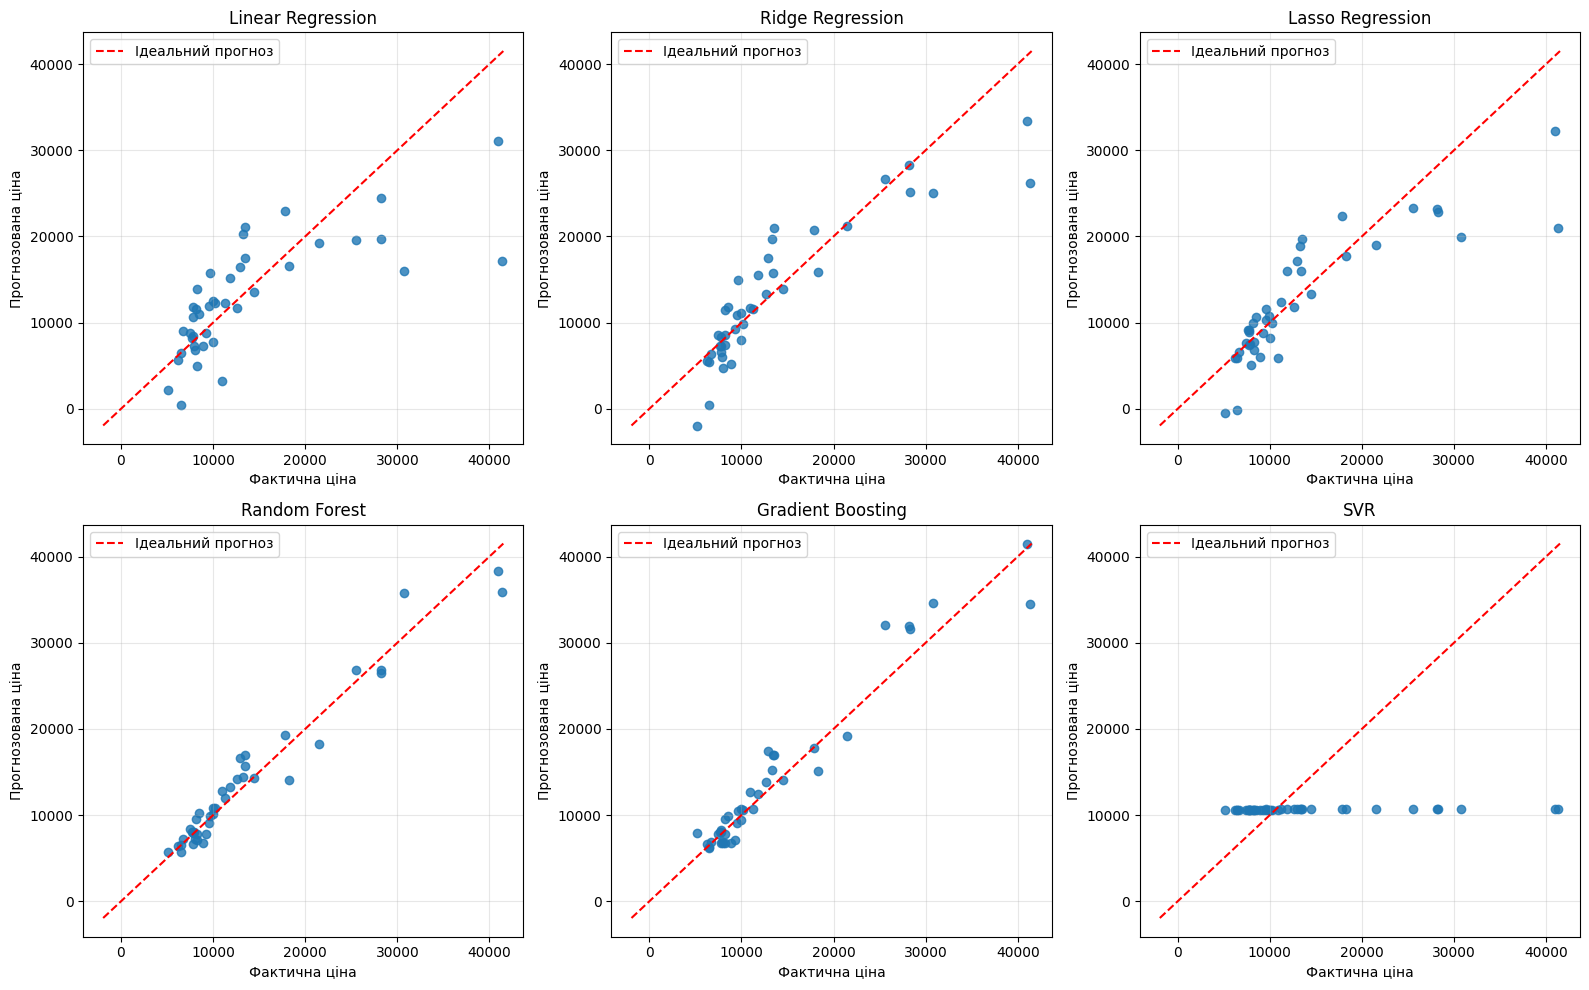

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

min_price = min(y_test.min(), min(pred.min() for pred in predictions.values()))
max_price = max(y_test.max(), max(pred.max() for pred in predictions.values()))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.8)
    ax.plot(
        [min_price, max_price],
        [min_price, max_price],
        "r--",
        label="Ідеальний прогноз"
    )
    ax.set_title(name)
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

На графіках найкращі результати показують Random Forest і Gradient Boosting: їхні прогнози розташовані ближче до лінії ідеального прогнозу. Для інших моделей відхилення помітніші

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [30]:
selected_index = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[selected_index]
y_actual = y_test.loc[selected_index]
sample_ids = id_test.loc[selected_index]

rf_model = pipelines["Random Forest"]
y_pred_rf = rf_model.predict(X_sample)

prediction_table = pd.DataFrame({
    "car_ID": sample_ids.to_numpy(),
    "Фактична ціна": y_actual.to_numpy(),
    "Прогнозована ціна": y_pred_rf,
    "Абсолютна помилка": np.abs(y_actual.to_numpy() - y_pred_rf),
    "Абсолютна помилка, %": (
        np.abs(y_actual.to_numpy() - y_pred_rf)
        / y_actual.to_numpy() * 100
    )
})

display(prediction_table.round(2))

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна помилка, %"
0,26,6692.0,7255.72,563.72,8.42
1,176,9988.0,10825.84,837.84,8.39
2,148,10198.0,10840.34,642.34,6.30
3,17,41315.0,35846.35,5468.65,13.24
4,69,28248.0,26518.14,1729.86,6.12
5,147,7463.0,8375.81,912.81,12.23
6,144,9960.0,10130.32,170.32,1.71
7,85,14489.0,14356.26,132.74,0.92
8,195,12940.0,16679.60,3739.60,28.90
9,160,7788.0,7904.18,116.18,1.49


Для більшості з 10 автомобілів прогнозовані ціни близькі до фактичних. Найбільша відсоткова помилка в цій вибірці становить 28,90%, а найменша — 0,92%

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


In [31]:
best_r2 = results_df.loc[results_df["R2"].idxmax()]
best_mae = results_df.loc[results_df["MAE"].idxmin()]
best_mse = results_df.loc[results_df["MSE"].idxmin()]
best_mape = results_df.loc[results_df["MAPE, %"].idxmin()]

print("Найкращий результат за R2:", best_r2["Модель"])
print("Найменша MAE:", best_mae["Модель"])
print("Найменша MSE:", best_mse["Модель"])
print("Найменша MAPE:", best_mape["Модель"])

#Різниця між R2 на train і test
results_df["Різниця R2"] = results_df["R2 train"] - results_df["R2"]

print("\nРізниця між R2 на train і test:")
display(
    results_df[["Модель", "R2 train", "R2", "Різниця R2"]].round(3)
)

Найкращий результат за R2: Random Forest
Найменша MAE: Random Forest
Найменша MSE: Random Forest
Найменша MAPE: Random Forest

Різниця між R2 на train і test:


,Модель,R2 train,R2,Різниця R2
0,Random Forest,0.985,0.951,0.035
1,Gradient Boosting,0.992,0.930,0.063
2,Ridge Regression,0.962,0.796,0.166
3,Lasso Regression,0.991,0.706,0.285
4,Linear Regression,0.993,0.548,0.445
5,SVR,-0.108,-0.100,-0.009


# **Висновок:**

У лабораторній роботі я дослідила дані про автомобілі
та побудувала шість моделей для прогнозування їхньої ціни.
Я перевірила якість даних, обробила потенційні викиди,
проаналізувала кореляції та виконала підготовку числових
і категоріальних ознак.За результатами тестування найкращий R2 показала модель
Random Forest (R2 = 0.951).

Найменше значення MAE отримала модель Random Forest
(1446.90), MSE — Random Forest
(3900438.62), а MAPE — Random Forest
(10.50%).

Порівняння R2 на навчальній і тестовій вибірках допомогло
оцінити можливе перенавчання моделей. Попередня обробка
даних дала змогу підготувати ознаки до навчання.
Я порівняла різні регресійні моделі та оцінила їхню
точність за допомогою кількох метрик. Отримані результати
допомогли визначити моделі, які краще прогнозують ціну
автомобілів на тестових даних

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
